# R(2+1)D Crime Detection Model - Violence/Theft/Normal Classification
## R(2+1)D-T Transformer with Full Training Pipeline and Performance Visualization


## 1. Import Required Libraries


In [68]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import gc
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")


PyTorch version: 2.9.0+cu126
Torchvision version: 0.24.0+cu126
CUDA available: True


## 2. Define Dataset Paths and Classes


In [69]:
RWF       = "/kaggle/input/datasets/daniazehra/rwf-2000/RWF-2000"
UCF_CRIME = "/kaggle/input/datasets/alirakhmaev/ucf-crime-full"
CAMNUVEOM = "/kaggle/input/datasets/mohamedelattar02/camnuveom2/camnuveom/videos/samples/training"

MAIN_CLASSES = ['violence', 'theft', 'normal']

UCF_TO_MAIN_CLASS = {
    'Shoplifting': 'theft',
    'Stealing':    'theft',
    'Robbery':     'theft',
    'Burglary':    'theft',
    'Normal':      'normal',
}

NUM_FRAMES = 16
IMG_SIZE   = 112

print(f"Main Classes: {MAIN_CLASSES}")
print(f"Number of Classes: {len(MAIN_CLASSES)}")


Main Classes: ['violence', 'theft', 'normal']
Number of Classes: 3


## 3. Data Loading Functions


In [70]:
def load_camnuveom():
    rows = []
    for cls in ["anomaly", "normal"]:
        class_dir = os.path.join(CAMNUVEOM, cls)
        if not os.path.exists(class_dir): continue
        main_label = "theft" if cls == "anomaly" else "normal"
        for video_path in glob.glob(os.path.join(class_dir, "*.mp4")):
            rows.append({'clip_path': video_path, 'main_label': main_label,
                         'sub_label': main_label, 'dataset': 'camnuveon',
                         'original_class': cls, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from CAMNUVEON")
    return df

def load_rwf():
    rows = []
    for split in ["train", "val"]:
        for cls in ["Fight", "NonFight"]:
            class_dir = os.path.join(RWF, split, cls)
            if not os.path.exists(class_dir): continue
            main_label = "violence" if cls == "Fight" else "normal"
            for video_path in glob.glob(os.path.join(class_dir, "*.avi")):
                rows.append({'clip_path': video_path, 'main_label': main_label,
                             'sub_label': main_label, 'dataset': 'RWF-2000',
                             'original_class': cls, 'split': split})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from RWF-2000")
    return df

def load_ucf():
    if not os.path.exists(UCF_CRIME): return None
    class_folders = [d for d in os.listdir(UCF_CRIME) if os.path.isdir(os.path.join(UCF_CRIME, d))]
    rows = []
    for class_name in class_folders:
        class_path = os.path.join(UCF_CRIME, class_name)
        main_label = UCF_TO_MAIN_CLASS.get(class_name)
        if main_label is None: continue
        videos = glob.glob(os.path.join(class_path, "*.mp4")) + glob.glob(os.path.join(class_path, "*.avi"))
        for video_path in videos:
            rows.append({'clip_path': video_path, 'main_label': main_label,
                         'sub_label': class_name.lower(), 'dataset': 'UCF-Crime',
                         'original_class': class_name, 'split': 'unknown'})
    df = pd.DataFrame(rows)
    print(f"✓ Loaded {len(df)} videos from UCF-Crime")
    return df


## 4. Load and Merge Datasets


In [71]:
print("\n" + "="*60 + "\nLOADING DATASETS\n" + "="*60)
rwf_df = load_rwf()
ucf_df = load_ucf()
cam_df = load_camnuveom()

df = pd.concat([rwf_df, ucf_df, cam_df], ignore_index=True)
df = df[df['main_label'].isin(MAIN_CLASSES)].copy()

print(f"\nTotal videos loaded: {len(df)}")
print("\n" + "="*60 + "\nDATASET DISTRIBUTION\n" + "="*60)
for cls in MAIN_CLASSES:
    count = len(df[df['main_label'] == cls])
    print(f"  {cls}: {count:4d} videos ({count / len(df) * 100:5.1f}%)")



LOADING DATASETS
✓ Loaded 2000 videos from RWF-2000
✓ Loaded 400 videos from UCF-Crime
✓ Loaded 874 videos from CAMNUVEON

Total videos loaded: 3274

DATASET DISTRIBUTION
  violence: 1000 videos ( 30.5%)
  theft:  837 videos ( 25.6%)
  normal: 1437 videos ( 43.9%)


## 5. R(2+1)D Dataset Class


In [72]:
class R2Plus1DCrimeDetectionDataset(Dataset):
    def __init__(self, dataframe, num_frames=16, img_size=224, is_train=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train
        self.label_to_idx = {label: idx for idx, label in enumerate(MAIN_CLASSES)}
        self.idx_to_label = {idx: label for label, idx in self.label_to_idx.items()}

    def __len__(self):
        return len(self.dataframe)

    def extract_frames(self, video_path):
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames < 1:
                cap.release(); return None

            if 'UCF-Crime' in video_path:
                start_frame = max(0, total_frames // 4)
                end_frame   = min(total_frames, 3 * total_frames // 4)
            else:
                start_frame, end_frame = 0, total_frames

            if end_frame <= start_frame:
                indices = [0] * self.num_frames
            else:
                indices = np.linspace(start_frame, end_frame - 1, self.num_frames, dtype=int)

            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = cv2.resize(frame, (self.img_size, self.img_size))
                    frames.append(frame.astype(np.float32) / 255.0)
                else:
                    frames.append(np.zeros((self.img_size, self.img_size, 3), dtype=np.float32))
            cap.release()
            if len(frames) == 0: return None

            frames = np.stack(frames, axis=0)
            frames = np.transpose(frames, (3, 0, 1, 2))
            return frames
        except:
            return None

    def __getitem__(self, idx):
        video_path = self.dataframe.loc[idx, 'clip_path']
        main_label = self.dataframe.loc[idx, 'main_label']
        frames = self.extract_frames(video_path)

        if frames is None:
            frames_tensor = torch.zeros((3, self.num_frames, self.img_size, self.img_size))
            label_idx = self.label_to_idx['normal']
        else:
            frames_tensor = torch.from_numpy(frames).float()
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1, 1)
            std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1, 1)
            frames_tensor = (frames_tensor - mean) / std
            label_idx = self.label_to_idx[main_label]
        return frames_tensor, label_idx, video_path


## 6. Create Data Splits (15% Test)


In [73]:
df = df.sample(frac=1).reset_index(drop=True)
NUM_CLASSES = len(MAIN_CLASSES)

train_val, test = train_test_split(
    df, test_size=0.15, stratify=df['main_label'], random_state=42
)
print(f"Train+Val: {len(train_val)} samples")
print(f"Test     : {len(test)} samples")


Train+Val: 2782 samples
Test     : 492 samples


## 7. Single Train/Val Split (80/20) Setup


In [74]:
BATCH_SIZE  = 8
NUM_WORKERS = 2

print("\n" + "="*60 + "\nSINGLE TRAIN/VAL SPLIT\n" + "="*60)
train_df, val_df = train_test_split(
    train_val, test_size=0.20, stratify=train_val['main_label'], random_state=38
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
print(f"  Train: {len(train_df)} | Val: {len(val_df)}")

train_dataset = R2Plus1DCrimeDetectionDataset(train_df, num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=True)
val_dataset   = R2Plus1DCrimeDetectionDataset(val_df,   num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)
test_dataset  = R2Plus1DCrimeDetectionDataset(test,     num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)




SINGLE TRAIN/VAL SPLIT
  Train: 2225 | Val: 557


## 8. R(2+1)D Model Creation


In [75]:
print("\n" + "="*60 + "\nR(2+1)D MODEL CREATION\n" + "="*60)

def r2plus1d_for_3class(num_classes=3):
    from torchvision.models.video import r2plus1d_18
    model = r2plus1d_18(weights='DEFAULT')
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = r2plus1d_for_3class(NUM_CLASSES).to(device)
print(f"\n✓ Model: {model.__class__.__name__}")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")




R(2+1)D MODEL CREATION
Using device: cuda

✓ Model: VideoResNet
  Parameters: 31,301,664


## 9. Training Functions


In [76]:
def train_epoch(model, loader, optimizer, criterion, device, epoch):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    class_correct = {c: 0 for c in MAIN_CLASSES}
    class_total   = {c: 0 for c in MAIN_CLASSES}
    pbar = tqdm(loader, desc=f'Train Epoch {epoch}')

    for batch_idx, (inputs, labels, _) in enumerate(pbar):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        _, pred = outputs.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()
        total_loss += loss.item()
        
        for i in range(len(labels)):
            c = MAIN_CLASSES[labels[i].item()]
            class_total[c] += 1
            if pred[i] == labels[i]: class_correct[c] += 1
            
        pbar.set_postfix({'Loss': f'{total_loss/(batch_idx+1):.4f}', 'Acc': f'{100.*correct/total:.1f}%'})

    print("  Per-class training accuracy:")
    for c in MAIN_CLASSES:
        if class_total[c] > 0: print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%")
    return total_loss/len(loader), 100.*correct/total

def validate(model, loader, criterion, device, mode='val'):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    class_correct, class_total = {c: 0 for c in MAIN_CLASSES}, {c: 0 for c in MAIN_CLASSES}

    with torch.no_grad():
        for inputs, labels, _ in tqdm(loader, desc=f'{mode.capitalize()} Eval'):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            _, pred = outputs.max(1)
            total += labels.size(0)
            correct += pred.eq(labels).sum().item()
            total_loss += loss.item()
            
            for i in range(len(labels)):
                c = MAIN_CLASSES[labels[i].item()]
                class_total[c] += 1
                if pred[i] == labels[i]: class_correct[c] += 1
            
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = 100.*correct/total
    print(f"  {mode.capitalize()} Loss: {total_loss/len(loader):.4f}, Accuracy: {acc:.1f}%")
    for c in MAIN_CLASSES:
        if class_total[c] > 0: print(f"    {c}: {100.*class_correct[c]/class_total[c]:.1f}%")
    return total_loss/len(loader), acc, all_preds, all_labels


## 10. Initialize Loss Function


In [77]:
criterion = nn.CrossEntropyLoss()
print(f"Loss function: {criterion.__class__.__name__}")


Loss function: CrossEntropyLoss


## 11. Training Loop (Single Split)


In [78]:
EPOCHS = 10
print("\n" + "="*60 + "\nTRAINING R(2+1)D MODEL\n" + "="*60)

optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

best_val_acc = 0
patience = 3
patience_ctr = 0
tr_losses, vl_losses, tr_accs, vl_accs = [], [], [], []

for epoch in range(1, EPOCHS + 1):
    tl, ta = train_epoch(model, train_loader, optimizer, criterion, device, epoch)
    vl, va, _, _ = validate(model, val_loader, criterion, device, 'val')
    tr_losses.append(tl); tr_accs.append(ta)
    vl_losses.append(vl); vl_accs.append(va)
    
    if va > best_val_acc:
        best_val_acc = va
        patience_ctr = 0
        torch.save(model.state_dict(), "/kaggle/working/best_r2plus1d.pth")
        print(f"  ✓ Best model saved (Val Acc: {va:.2f}%)")
    else:
        patience_ctr += 1
        print(f"  ✗ No improvement ({patience_ctr}/{patience})")
        if patience_ctr >= patience:
            print("  EARLY STOPPING TRIGGERED")
            break
    scheduler.step()
    
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()




TRAINING R(2+1)D MODEL


Train Epoch 1: 100%|██████████| 278/278 [10:14<00:00,  2.21s/it, Loss=0.7369, Acc=66.7%]


  Per-class training accuracy:
    violence: 66.4%
    theft: 57.8%
    normal: 72.0%


Val Eval: 100%|██████████| 70/70 [02:39<00:00,  2.27s/it]


  Val Loss: 0.4009, Accuracy: 84.0%
    violence: 88.8%
    theft: 65.5%
    normal: 91.4%
  ✓ Best model saved (Val Acc: 84.02%)


...

  Val Loss: 0.2824, Accuracy: 88.9%
    violence: 87.1%
    theft: 88.0%
    normal: 90.6%
  ✗ No improvement (2/3)


Train Epoch 7: 100%|██████████| 278/278 [08:49<00:00,  1.91s/it, Loss=0.0831, Acc=97.5%]


  Per-class training accuracy:
    violence: 95.6%
    theft: 97.4%
    normal: 99.0%


Val Eval: 100%|██████████| 70/70 [02:14<00:00,  1.92s/it]

  Val Loss: 0.2920, Accuracy: 88.7%
    violence: 87.6%
    theft: 81.7%
    normal: 93.5%
  ✗ No improvement (3/3)
  EARLY STOPPING TRIGGERED


## 12. Evaluate on Test Set


In [80]:
print("\n" + "="*60 + "\nTEST SET EVALUATION\n" + "="*60)

best_model = r2plus1d_for_3class(NUM_CLASSES)
best_model.load_state_dict(torch.load("/kaggle/working/best_r2plus1d.pth"))

best_model = best_model.to(device)

test_loss, test_acc, test_preds, test_labels = validate(best_model, test_loader, criterion, device, 'test')
print(f"\nFinal Test Accuracy: {test_acc:.2f}%")



TEST SET EVALUATION


Test Eval: 100%|██████████| 62/62 [01:52<00:00,  1.81s/it]

  Test Loss: 0.3701, Accuracy: 85.8%
    violence: 92.7%
    theft: 81.0%
    normal: 83.8%

Final Test Accuracy: 85.77%


## 13. Detailed Performance Metrics


In [81]:
print("\n" + "="*60 + "\nCLASSIFICATION REPORT\n" + "="*60)
print(classification_report(test_labels, test_preds, target_names=MAIN_CLASSES, digits=4))



CLASSIFICATION REPORT
              precision    recall  f1-score   support

    violence     0.8742    0.9267    0.8997       150
       theft     0.8095    0.8095    0.8095       126
      normal     0.8744    0.8380    0.8558       216

    accuracy                         0.8577       492
   macro avg     0.8527    0.8581    0.8550       492
weighted avg     0.8577    0.8577    0.8573       492



## 14. Confusion Matrix Visualization


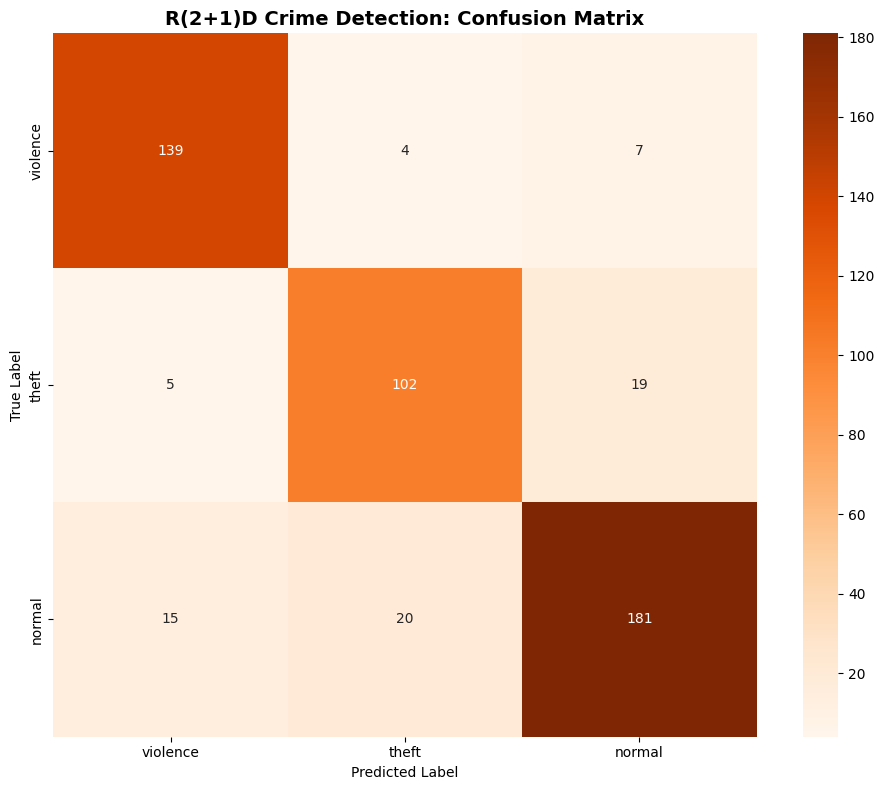

In [82]:
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=MAIN_CLASSES, yticklabels=MAIN_CLASSES, square=True)
plt.title('R(2+1)D Crime Detection: Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('/kaggle/working/r21d_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


## 15. Training History Visualization


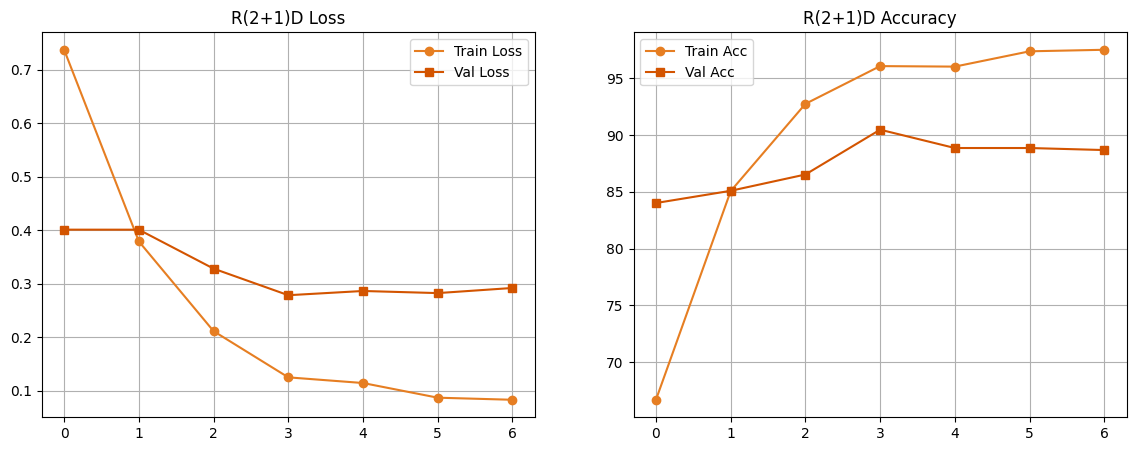

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tr_losses, 'o-', label='Train Loss', color='#e67e22')
axes[0].plot(vl_losses, 's-', label='Val Loss',   color='#d35400')
axes[0].set_title('R(2+1)D Loss'); axes[0].grid(True); axes[0].legend()

axes[1].plot(tr_accs, 'o-', label='Train Acc', color='#e67e22')
axes[1].plot(vl_accs, 's-', label='Val Acc',   color='#d35400')
axes[1].set_title('R(2+1)D Accuracy'); axes[1].grid(True); axes[1].legend()
plt.show()


## 16. Benchmark Summary


In [84]:
f1   = f1_score(test_labels, test_preds, average='macro')
prec = precision_score(test_labels, test_preds, average='macro')
rec  = recall_score(test_labels, test_preds, average='macro')

print("\n" + "="*60 + "\nSWIN3D BENCHMARK RESULTS\n" + "="*60)
print(f"  Model            : R(2+1)D-T")
print(f"  Frames per clip  : {NUM_FRAMES}")
print(f"  Image size       : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Epochs           : {EPOCHS}")
print(f"  Best Val Acc     : {best_val_acc:.2f}%")
print(f"  Test Accuracy    : {test_acc:.2f}%")
print(f"  Macro F1-Score   : {f1:.4f}")
print(f"  Macro Precision  : {prec:.4f}")
print(f"  Macro Recall     : {rec:.4f}")
print("="*60)



SWIN3D BENCHMARK RESULTS
  Model            : R(2+1)D-T
  Frames per clip  : 16
  Image size       : 112x112
  Epochs           : 10
  Best Val Acc     : 90.48%
  Test Accuracy    : 85.77%
  Macro F1-Score   : 0.8550
  Macro Precision  : 0.8527
  Macro Recall     : 0.8581
